# 01 – Dataset Exploration and Data Preparation

**Dataset:** Hotel Booking Demand (Kaggle)  
**Target:** `is_canceled` (`0` = not cancelled, `1` = cancelled)  
**Objective:** Explore the original dataset, document data-quality decisions, create one reproducible stratified 80:20 split, and export the held-out test set required by the assignment.

**Execution order:** Run this notebook first, from either the repository root or the `notebooks/` folder. It creates `data/train_data.csv`, `test_data.csv`, EDA summary CSVs, and a target-distribution chart.

**Leakage prevention:** This notebook performs only deterministic cleaning before the split. Imputers, encoders and scalers are not fitted here. The five model notebooks must fit their preprocessing pipelines on `train_data.csv` only and then transform `test_data.csv` with the already-fitted pipeline.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET = "is_canceled"
LEAKAGE_COLUMNS = ["reservation_status", "reservation_status_date"]

# Locate the project root whether the notebook is run from the root or notebooks/.
root_candidates = [Path.cwd(), Path.cwd().parent]
REPO_ROOT = next(
    (path.resolve() for path in root_candidates if (path / "data" / "hotel_bookings.csv").exists()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError(
        "Could not locate data/hotel_bookings.csv. Run this notebook from the repository root or notebooks/ folder."
    )

DATA_PATH = REPO_ROOT / "data" / "hotel_bookings.csv"
RESULTS_DIR = REPO_ROOT / "results"
PLOTS_DIR = RESULTS_DIR / "visualizations"
RESULTS_DIR.mkdir(exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Load the original CSV.
df = pd.read_csv(DATA_PATH)

if TARGET not in df.columns:
    raise KeyError(f"Target column {TARGET!r} was not found.")
if df[TARGET].isna().any():
    raise ValueError("The target column contains missing values; inspect them before proceeding.")
if set(df[TARGET].unique()) != {0, 1}:
    raise ValueError(f"Expected a binary 0/1 target, found: {sorted(df[TARGET].unique())}")

print(f"Project root: {REPO_ROOT}")
print(f"Loaded file: {DATA_PATH.name}")
print(f"Original dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())


Project root: /home/s2026ct05092/Downloads/ML-Assignment-2
Loaded file: hotel_bookings.csv
Original dataset shape: 119,390 rows × 32 columns


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 1. Dataset overview and feature types

The dataset contains hotel booking records. The target variable is `is_canceled`. We inspect the shape, data types and descriptive statistics before making cleaning decisions.

In [2]:
overview = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True),
})
overview.index.name = "column"
display(overview)

display(df.describe(include="all").T)

print("Numerical columns:", int(df.select_dtypes(include="number").shape[1]))
print("Categorical/object columns:", int(df.select_dtypes(include=["object", "category"]).shape[1]))


,data_type,missing_count,missing_percent,unique_values
column,,,,
hotel,object,0,0.00,2
is_canceled,int64,0,0.00,2
lead_time,int64,0,0.00,479
arrival_date_year,int64,0,0.00,3
arrival_date_month,object,0,0.00,12
arrival_date_week_number,int64,0,0.00,53
arrival_date_day_of_month,int64,0,0.00,31
stays_in_weekend_nights,int64,0,0.00,17
stays_in_week_nights,int64,0,0.00,35


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
column,,,,,,,,,,,
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0


Numerical columns: 20
Categorical/object columns: 12


## 2. Missing-value analysis

Missing values are handled according to feature meaning. The highly sparse `company` field will be excluded. Missing `children`, `country` and `agent` values are retained in the split and imputed within each model's training-only preprocessing pipeline.

,missing_count,missing_percent
column,,
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


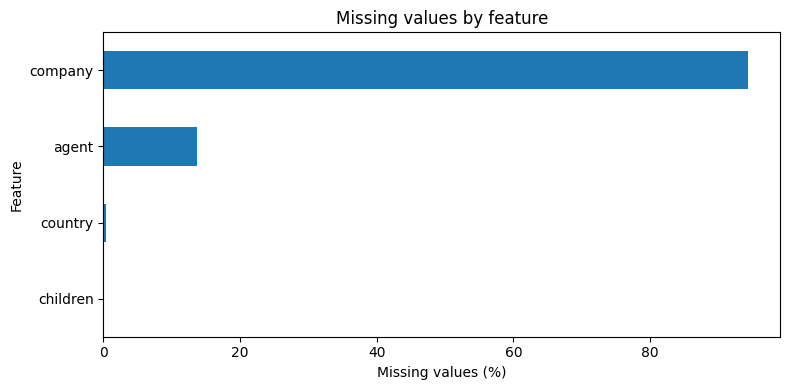

In [3]:
missing_summary = (
    df.isna().sum()
      .rename("missing_count")
      .to_frame()
      .assign(missing_percent=lambda table: (table["missing_count"] / len(df) * 100).round(2))
      .query("missing_count > 0")
      .sort_values("missing_percent", ascending=False)
)
display(missing_summary)
missing_summary.to_csv(RESULTS_DIR / "eda_missing_values.csv")

ax = missing_summary["missing_percent"].sort_values().plot(kind="barh", figsize=(8, 4))
ax.set_title("Missing values by feature")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "missing_values.png", dpi=160, bbox_inches="tight")
plt.show()


## 3. Duplicate-row analysis

The assignment requires duplicates to be identified and handled. The CSV does not provide a unique booking identifier, so identical rows cannot be proven to be accidental duplicates rather than separate bookings with identical recorded attributes. For this experiment, exact duplicate rows across all original columns are removed, and this limitation is disclosed in the report.

In [4]:
duplicate_count = int(df.duplicated().sum())
duplicate_percent = duplicate_count / len(df) * 100
print(f"Exact duplicate rows: {duplicate_count:,} ({duplicate_percent:.2f}%)")

print("Target distribution before duplicate removal:")
raw_target = df[TARGET].value_counts().sort_index()
raw_target_summary = pd.DataFrame({
    "count": raw_target,
    "percent": (raw_target / len(df) * 100).round(2),
})
display(raw_target_summary)


Exact duplicate rows: 31,994 (26.80%)
Target distribution before duplicate removal:


,count,percent
is_canceled,,
0,75166,62.96
1,44224,37.04


## 4. Target class distribution and imbalance

We inspect the target before and after exact duplicate removal. Class imbalance is not extreme, but the minority class is smaller. A stratified split will preserve class proportions in both partitions. We will report multiple metrics (including precision, recall, F1, AUC and MCC), not accuracy alone.

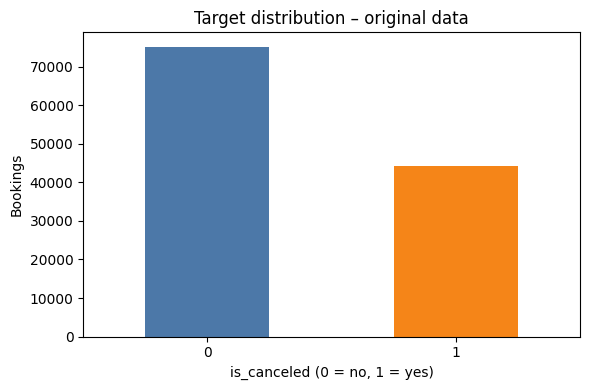

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
raw_target.sort_index().plot(kind="bar", ax=ax, color=["#4C78A8", "#F58518"], rot=0)
ax.set_title("Target distribution – original data")
ax.set_xlabel("is_canceled (0 = no, 1 = yes)")
ax.set_ylabel("Bookings")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "target_distribution_original.png", dpi=160, bbox_inches="tight")
plt.show()


## 5. Cleaning decisions

Apply the following decisions consistently in all five model notebooks:

1. **Exact duplicates:** remove exact duplicate rows across all original columns (`drop_duplicates`). The dataset has no unique booking ID, so the limitation is documented.
2. **Target leakage:** remove `reservation_status` and `reservation_status_date`. These fields describe the booking's final outcome and would reveal the target.
3. **Very sparse feature:** remove `company` because 94.31% of its values are missing. This is a modelling choice; its potential information is sacrificed to avoid relying on an extremely sparse identifier field.
4. **Agent identifier:** treat `agent` as a categorical identifier, not a continuous numeric measurement. Convert non-missing codes to labels such as `Agent_9`; missing entries remain missing for pipeline imputation.
5. **Invalid ADR:** the source has one negative `adr` value. Treat it as missing and impute it using a statistic learned from training data in each model pipeline.
6. **Other missing values:** retain missing `children`, `country` and `agent` values. Model pipelines must impute numerical values using the training median and categorical values with a constant such as `Unknown`.
7. **Unusual zero-adult bookings:** do not automatically delete these rows; flag the issue for interpretation because the source has no booking ID or further context to verify whether the records are invalid.

After excluding the two leakage columns and `company`, some previously distinct rows can have identical remaining feature values. We keep those rows because they were not exact duplicates in the original source; the omitted columns distinguished them. All learned preprocessing (imputation, encoding and scaling) must occur after the split and be fitted on the training data only.

,step,rows,columns_including_target,decision
0,Original rows,119390,32,Original downloaded dataset
1,After exact duplicate removal,87396,32,Removed exact duplicate rows
2,Final modelling table,87396,29,Excluded two leakage fields and sparse company...


Removed exact duplicate rows: 31,994
Company missing in original data: 94.31%
Negative ADR values converted to missing: 1
Zero-adult rows retained: 385
Rows that look duplicated only after excluded columns are removed (retained): 266
Final cleaned shape: 87,396 rows × 29 columns
Predictor count (excluding target): 28
Remaining missing values (to be handled in model pipelines):


,missing_count
column,
children,4
country,452
agent,12193
adr,1


,count,percent
is_canceled,,
0,63371,72.51
1,24025,27.49


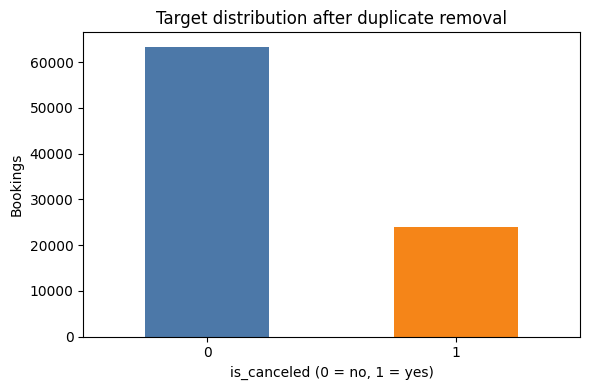

In [6]:
cleaned_df = df.drop_duplicates().copy()
rows_after_deduplication = len(cleaned_df)

# Remove target leakage / post-outcome fields.
missing_leakage_columns = [column for column in LEAKAGE_COLUMNS if column not in cleaned_df.columns]
if missing_leakage_columns:
    raise KeyError(f"Expected leakage columns are missing: {missing_leakage_columns}")
cleaned_df = cleaned_df.drop(columns=LEAKAGE_COLUMNS)

# Drop company because 94.31% of the original values are missing.
company_missing_percent = float(df["company"].isna().mean() * 100) if "company" in df.columns else np.nan
if "company" in cleaned_df.columns:
    cleaned_df = cleaned_df.drop(columns=["company"])

# Agent is an identifier/category, not a continuous measurement.
cleaned_df["agent"] = cleaned_df["agent"].map(
    lambda value: f"Agent_{int(value)}" if pd.notna(value) else pd.NA
).astype("string")

# Negative ADR is invalid for this dataset; convert it to missing for later
# training-only median imputation rather than using the test data to estimate a value.
negative_adr_count = int((cleaned_df["adr"] < 0).sum())
cleaned_df.loc[cleaned_df["adr"] < 0, "adr"] = np.nan

# Do not silently remove zero-adult records; record their count for discussion.
zero_adult_count = int((cleaned_df["adults"] == 0).sum())

if cleaned_df[TARGET].isna().any():
    raise ValueError("Target has missing values after cleaning.")
# Dropping columns can make previously distinct source rows look identical.
# Keep these rows: they were not exact duplicates in the original full dataset.
retained_feature_duplicate_count = int(cleaned_df.duplicated().sum())
if any(column in cleaned_df.columns for column in LEAKAGE_COLUMNS):
    raise AssertionError("A target-leakage column remains in the modelling data.")

feature_columns = [column for column in cleaned_df.columns if column != TARGET]
cleaning_summary = pd.DataFrame([
    {"step": "Original rows", "rows": len(df), "columns_including_target": df.shape[1], "decision": "Original downloaded dataset"},
    {"step": "After exact duplicate removal", "rows": rows_after_deduplication, "columns_including_target": df.shape[1], "decision": "Removed exact duplicate rows"},
    {"step": "Final modelling table", "rows": len(cleaned_df), "columns_including_target": cleaned_df.shape[1], "decision": "Excluded two leakage fields and sparse company field"},
])
display(cleaning_summary)
cleaning_summary.to_csv(RESULTS_DIR / "cleaning_summary.csv", index=False)

print(f"Removed exact duplicate rows: {duplicate_count:,}")
print(f"Company missing in original data: {company_missing_percent:.2f}%")
print(f"Negative ADR values converted to missing: {negative_adr_count}")
print(f"Zero-adult rows retained: {zero_adult_count}")
print(f"Rows that look duplicated only after excluded columns are removed (retained): {retained_feature_duplicate_count}")
print(f"Final cleaned shape: {cleaned_df.shape[0]:,} rows × {cleaned_df.shape[1]} columns")
print(f"Predictor count (excluding target): {len(feature_columns)}")
print("Remaining missing values (to be handled in model pipelines):")
display(cleaned_df.isna().sum().loc[lambda values: values > 0].rename("missing_count").to_frame())

clean_target = cleaned_df[TARGET].value_counts().sort_index()
clean_target_summary = pd.DataFrame({
    "count": clean_target,
    "percent": (clean_target / len(cleaned_df) * 100).round(2),
})
clean_target_summary.index.name = TARGET
display(clean_target_summary)
clean_target_summary.to_csv(RESULTS_DIR / "class_distribution_after_cleaning.csv")

fig, ax = plt.subplots(figsize=(6, 4))
clean_target.plot(kind="bar", ax=ax, color=["#4C78A8", "#F58518"], rot=0)
ax.set_title("Target distribution after duplicate removal")
ax.set_xlabel("is_canceled (0 = no, 1 = yes)")
ax.set_ylabel("Bookings")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "target_distribution_after_cleaning.png", dpi=160, bbox_inches="tight")
plt.show()


## 6. Stratified 80:20 train-test split and export

The split is created once using `stratify=y` and `random_state=42`. The raw cleaned predictors are saved before learned transformations. This means each model notebook can fit its own imputer, encoder and scaler on the same training partition, then apply those fitted transformations to the same held-out test partition.

In [7]:
X = cleaned_df.drop(columns=[TARGET]).copy()
y = cleaned_df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

train_data = X_train.copy()
train_data[TARGET] = y_train

test_data = X_test.copy()
test_data[TARGET] = y_test

train_path = REPO_ROOT / "data" / "train_data.csv"
test_path = REPO_ROOT / "test_data.csv"
train_data.to_csv(train_path, index=False)
test_data.to_csv(test_path, index=False)

print(f"Training partition: {train_data.shape[0]:,} rows × {train_data.shape[1]} columns")
print(f"Held-out test partition: {test_data.shape[0]:,} rows × {test_data.shape[1]} columns")
print(f"Saved training data: {train_path.relative_to(REPO_ROOT)}")
print(f"Saved required test data: {test_path.relative_to(REPO_ROOT)}")

split_summary = pd.DataFrame({
    "train_count": y_train.value_counts().sort_index(),
    "train_percent": (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    "test_count": y_test.value_counts().sort_index(),
    "test_percent": (y_test.value_counts(normalize=True).sort_index() * 100).round(2),
})
split_summary.index.name = TARGET
display(split_summary)
split_summary.to_csv(RESULTS_DIR / "train_test_class_distribution.csv")

# Validate split sizes, class presence and absence of target leakage.
assert len(train_data) + len(test_data) == len(cleaned_df)
assert len(test_data) == int(np.ceil(len(cleaned_df) * TEST_SIZE))
assert set(train_data[TARGET].unique()) == {0, 1}
assert set(test_data[TARGET].unique()) == {0, 1}
assert not any(column in train_data.columns for column in LEAKAGE_COLUMNS)
assert list(train_data.columns) == list(test_data.columns)
assert train_data.index.intersection(test_data.index).empty

print("Validation passed: 80:20 split, both classes represented, matching columns, and no row-index overlap.")


Training partition: 69,916 rows × 29 columns
Held-out test partition: 17,480 rows × 29 columns
Saved training data: data/train_data.csv
Saved required test data: test_data.csv


,train_count,train_percent,test_count,test_percent
is_canceled,,,,
0,50696,72.51,12675,72.51
1,19220,27.49,4805,27.49


Validation passed: 80:20 split, both classes represented, matching columns, and no row-index overlap.


## 7. Final preparation checklist and hand-off

Before running any model notebook, confirm that this notebook has completed without errors and created:

- `data/train_data.csv` – the 80% training partition.
- `test_data.csv` – the 20% held-out test partition, including `is_canceled`.
- `results/eda_missing_values.csv` and `results/cleaning_summary.csv`.
- `results/class_distribution_after_cleaning.csv` and `results/train_test_class_distribution.csv`.
- `results/visualizations/` – EDA plots.

**Important:** Do not fit imputers, encoders or scalers on the test partition. Each of the five model notebooks must load the same two CSV files and fit its preprocessing pipeline only on the training partition. The `test_data.csv` file must remain untouched for final evaluation.